In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import dask.array as da
import dask
import zarr
import xarray as xr
import cftime
import os

In [18]:
# # ============== LOAD LLC ==============
# llc_path = '/orcd/data/abodner/002/cody/LLC_patch/LLC4320_face1_i2880-3600_j720-1440.zarr'
# llc_patch_full = xr.open_zarr(llc_path)

llc_patch_full = xr.open_zarr('/orcd/data/abodner/003/LLC4320/LLC4320',consolidated=False).isel(
    face=1,
    i=slice(2880,3600),
    i_g=slice(2880,3600),
    j=slice(720,1440),
    j_g=slice(720,1440),
)
# quad: i=[2880:4320), j=[0:1440)
# Agulhas: i=[2880:3600), j=[720:1440)
# ============== LOAD EMULATORS ==============
emulator_configs = [
    {
        'name': 'eta-cheating',
        'key': 'emulator_1',
        'path': '/orcd/data/abodner/002/cody/inference_patch/2026-09-12-eval:samudra_rb_llc:1-tile-freshwaterflux_eager_rb-22637594/predictions_4d.zarr',
        'desc': ''
    },
    {
        'name': 'eta_fix',
        'key': 'emulator_2',
        'path': '/orcd/data/abodner/002/cody/inference_patch/2026-09-20-eval:samudra_rb_llc:1-tile-freshwater_flux-eagerRB-fully-trained-eta-fix-23265276/predictions_4d.zarr',
        'desc': ''
    },

]


# ============== OPEN EMULATOR DATASETS ==============
emulator_patches_raw = {}
for cfg in emulator_configs:
    emulator_patches_raw[cfg['key']] = xr.open_dataset(cfg['path'], consolidated=True)
    print(f"Loaded {cfg['name']}: {cfg['desc']}")

# ============== TIME MATCHING ==============
def normalize_times(times):
    return pd.DatetimeIndex([
        pd.Timestamp(
            int(t.year), int(t.month), int(t.day),
            int(t.hour), int(t.minute), int(t.second)
        )
        if hasattr(t, "year")
        else pd.Timestamp(t).floor("s")
        for t in times
    ])

llc_times_norm = normalize_times(llc_patch_full.time.values)

common_times = llc_times_norm
for cfg in emulator_configs:
    emulator_times_norm = normalize_times(emulator_patches_raw[cfg['key']].time.values)
    common_times = common_times.intersection(emulator_times_norm)

common_times = common_times.sort_values()

llc_mask = llc_times_norm.isin(common_times)
llc_patch = llc_patch_full.isel(time=llc_mask)

print(f"LLC subset to {len(common_times)} common times")

# ============== PORT GRID VARS & BUILD UNIFIED STRUCTURE ==============
grid_vars = ['XC', 'YC', 'rA', 'Z']

emulator_patches = {}
for cfg in emulator_configs:
    patch_raw = emulator_patches_raw[cfg['key']]
    patch_times_norm = normalize_times(patch_raw.time.values)

    patch_mask = patch_times_norm.isin(common_times)
    patch = patch_raw.isel(time=patch_mask)

    for gv in grid_vars:
        patch[gv] = llc_patch[gv]

    emulator_patches[cfg['key']] = patch

# ============== UNIFIED REFERENCE LISTS ==============
emulator_info = [(cfg['name'], cfg['key']) for cfg in emulator_configs]
n_emulators = len(emulator_info)

all_patches = {'llc': llc_patch}
all_patches.update(emulator_patches)

print(f"\n=== Setup complete: LLC + {n_emulators} emulators ===")
for name, key in emulator_info:
    print(f"  {name} ({key})")

Loaded eta-cheating: 
Loaded eta_fix: 
LLC subset to 744 common times

=== Setup complete: LLC + 2 emulators ===
  eta-cheating (emulator_1)
  eta_fix (emulator_2)


In [19]:
# ============== LOAD Eta FROM predictions.zarr ==============
# The repacked `_4d.zarr` only carries the 3D fields (U, V, Theta, Salt); Eta
# lives in the flat `predictions.zarr` beside it as (time, lat, lon). Derive
# that path from the one already in `emulator_configs` so there is still only
# one path per emulator to edit.
import os

for cfg in emulator_configs:
    eta_path = cfg['path'].replace('predictions_4d.zarr', 'predictions.zarr')
    if not os.path.exists(eta_path):
        print(f"  !! no predictions.zarr for {cfg['name']}: {eta_path}")
        continue
    try:
        eta_ds = xr.open_zarr(eta_path, consolidated=True)
    except Exception:
        eta_ds = xr.open_zarr(eta_path, consolidated=False)

    # Align to the 4d store's own time axis, then attach. Both were written by
    # the same eval run so they share a time axis, but match on values rather
    # than assume it -- a truncated or resumed eval would otherwise silently
    # pair Eta with the wrong step.
    tgt = normalize_times(emulator_patches_raw[cfg['key']].time.values)
    src = normalize_times(eta_ds.time.values)
    if not src.equals(tgt):
        keep = src.isin(tgt)
        eta_ds = eta_ds.isel(time=keep)
        src = normalize_times(eta_ds.time.values)
        if not src.equals(tgt):
            raise ValueError(
                f"{cfg['name']}: Eta time axis ({len(src)}) cannot be matched to "
                f"the 4d store's ({len(tgt)})."
            )

    eta = eta_ds['Eta']
    # Ride on the 4d store's own time coordinate so the later isel-based
    # subsetting lines up index-for-index.
    eta = eta.assign_coords(time=emulator_patches_raw[cfg['key']].time.values)
    emulator_patches_raw[cfg['key']]['Eta'] = eta
    emulator_patches[cfg['key']]['Eta'] = eta.isel(
        time=normalize_times(eta.time.values).isin(common_times)
    )
    print(f"  loaded Eta for {cfg['name']}: {eta.shape}")

# LLC truth already carries Eta from the raw store.
print(f"\nEta present -> llc: {'Eta' in llc_patch}, "
      + ", ".join(f"{n}: {'Eta' in emulator_patches[k]}" for n, k in emulator_info))

  loaded Eta for eta-cheating: (744, 720, 720)
  loaded Eta for eta_fix: (744, 720, 720)

Eta present -> llc: True, eta-cheating: True, eta_fix: True


In [20]:
selected_time_range = [300, 400]   # inclusive indices
stepping = 1                    # 1 = every timestep, 4 = every 4th timestep
                                # 4 is the diagnostic default: 186 points over
                                # 31 days, ~4x less I/O. Set 1 for publication.

start_idx, end_idx = selected_time_range

# Keep a pristine full-length copy the first time this runs and always subset
# from THAT. This cell used to reassign llc_patch/emulator_patches in place, so
# running it twice subset an already-subset axis: with stepping=4 a second run
# silently gave every 16th step, a third every 64th, and the x-axis quietly
# shrank (744 -> 186 -> 47 -> 12 ...).
try:
    _FULL_LLC, _FULL_EMU
except NameError:
    _FULL_LLC = llc_patch
    _FULL_EMU = dict(emulator_patches)
llc_patch = _FULL_LLC
emulator_patches = dict(_FULL_EMU)

# ----------------------------------------
# First subset LLC
# ----------------------------------------
llc_patch = llc_patch.isel(
    time=slice(start_idx, end_idx + 1, stepping)
)

# ----------------------------------------
# Then subset each emulator safely
# Handles shorter emulator runs automatically
# ----------------------------------------
emulator_patches_subset = {}

for key, patch in emulator_patches.items():

    max_time = patch.sizes['time']

    # Prevent indexing past emulator length
    safe_end_idx = min(end_idx, max_time - 1)

    patch_subset = patch.isel(
        time=slice(start_idx, safe_end_idx + 1, stepping)
    )

    emulator_patches_subset[key] = patch_subset

emulator_patches = emulator_patches_subset

# ----------------------------------------
# Match LLC length to shortest emulator
# ----------------------------------------
min_time_len = min(
    [llc_patch.sizes['time']] +
    [patch.sizes['time'] for patch in emulator_patches.values()]
)

llc_patch = llc_patch.isel(time=slice(0, min_time_len))

emulator_patches = {
    key: patch.isel(time=slice(0, min_time_len))
    for key, patch in emulator_patches.items()
}

# ----------------------------------------
# Rebuild combined dict
# ----------------------------------------
all_patches = {'llc': llc_patch}
all_patches.update(emulator_patches)

# ----------------------------------------
# Diagnostics
# ----------------------------------------
print(f"Subset to time indices {start_idx}:{end_idx}")
print(f"Stepping = {stepping}")
print(f"Final synchronized length = {min_time_len}")

print(f"LLC now has {llc_patch.sizes['time']} times")

for name, key in emulator_info:
    print(
        f"{name} ({key}) now has "
        f"{emulator_patches[key].sizes['time']} times"
    )

Subset to time indices 300:400
Stepping = 1
Final synchronized length = 101
LLC now has 101 times
eta-cheating (emulator_1) now has 101 times
eta_fix (emulator_2) now has 101 times


In [21]:
def as_dask(x):
    return x.data if isinstance(x.data, da.Array) else da.from_array(x.data)

def safe_norm(num, den):
    return da.where((den == 0) | da.isnan(den), np.nan, num / den)


In [22]:
# ============== AR-STABILITY CONFIG + STREAMING STATS ==============
import concurrent.futures as cf, time as _time, warnings

# Row 0 is the whole-column aggregate; the remaining rows are individual
# levels. Edit these lists and every figure below follows.
#
# DIAGNOSTIC DEFAULTS, ~9x less read than the full config:
#   * `stepping = 4` in the time-subset cell above (186 points over 31 days).
#     This is the knob that actually scales everything.
#   * DEPTH_AVERAGE strides the column by 5 (11 of 51 levels). NOTE this only
#     helps the EMULATOR stores, which are chunked (4, 1, 720, 720) -- one
#     level per chunk. The LLC truth store is chunked (1, 51, 1, 720, 720), so
#     one chunk holds the whole column and striding k decompresses exactly the
#     same bytes. Truth is therefore ~79 GB of the ~113 GB either way, and is
#     the floor on this cell; DEPTH_AVERAGE = slice(0, 51) costs truth nothing
#     extra and only triples the emulator read.
# For a publication run: DEPTH_AVERAGE = slice(0, 51), stepping = 1.
DEPTH_AVERAGE = slice(0, 51, 5)       # row 0: depth-average over these levels
DEPTH_LEVELS  = [0, 10, 25, 50]       # one row per level, below row 0
PLOT_VARS     = ['Theta', 'Salt', 'U', 'V', 'Eta']
TIME_BLOCK    = 48                    # timesteps resident per source
READ_WORKERS  = 24                    # concurrent block reads. Purely I/O
                                      # bound (measured 5% of one core), and
                                      # NFS throughput scales with concurrent
                                      # readers here: ~0.44 GB/s at 1 reader
                                      # vs ~2.8 GB/s at 16. Set near your CPU
                                      # count.

UNITS   = {'Theta': '°C', 'Salt': 'psu', 'U': 'm s$^{-1}$',
           'V': 'm s$^{-1}$', 'Eta': 'm'}
OUT_DIR = 'figs/AR-stability'
os.makedirs(OUT_DIR, exist_ok=True)

ROW_LABELS = [f"column mean\nk[{DEPTH_AVERAGE.start}:{DEPTH_AVERAGE.stop}"
              + (f":{DEPTH_AVERAGE.step}]" if DEPTH_AVERAGE.step else "]")] + \
             [f"k = {k}" for k in DEPTH_LEVELS]
N_ROWS, N_COLS = len(ROW_LABELS), len(PLOT_VARS)
SOURCES = [('llc', llc_patch)] + [(k, emulator_patches[k]) for _, k in emulator_info]
_PATCH = dict(SOURCES)

# Read ONLY the union of levels any row needs, once per time block, and derive
# every row from it.
#
# Why this is a loop and not a dask graph: an earlier version built one lazy
# reduction per (stat, var, row, source) and computed them together. Because a
# std needs its own mean first, dask kept each full (time, 51, 720, 720) array
# resident rather than streaming it -- ~1 TB of RSS for the full config, which
# OOMs long before it finishes. Blocking explicitly bounds peak memory to
# roughly TIME_BLOCK x len(LEVELS_TO_READ) x 720 x 720 x 8 B per in-flight read.
_AVG = list(range(*DEPTH_AVERAGE.indices(51)))
LEVELS_TO_READ = sorted(set(_AVG) | set(DEPTH_LEVELS))
_POS = {k: i for i, k in enumerate(LEVELS_TO_READ)}
_AVG_POS = [_POS[k] for k in _AVG]

_rA = np.asarray(llc_patch['rA'].values, dtype='f8')
AREA_W = _rA / _rA.sum()

# ---------------------------------------------------------------- NaN policy
# Every statistic below is computed over FINITE cells only, with the area
# weights renormalized to whatever survives. That makes a NaN mean exactly
# "no data here", which is what land is:
#   * the packed caches and the tiled eval write land as NaN (by design -- 0 is
#     a legitimate value for a normalized field, NaN is not);
#   * a blown-up rollout produces NaN/inf, and those cells must not silently
#     drag a domain mean to NaN or an RMSE to inf. They drop out, and
#     `valid_frac` below records how much of the domain was usable so a
#     shrinking denominator is visible rather than hidden.
# inf is treated as missing too: np.isfinite, not np.isnan.

def _wstats(x, ok=None):
    """Area-weighted (mean, std) over valid cells. x: (nb, ny, nx).

    `ok` lets every source share ONE validity mask, taken from the truth.
    That matters at depth: below the seafloor the truth is NaN but the
    emulators hold exactly 0.0 (eval fills masked cells with
    `data.masked_fill_value`, not NaN). Left to its own finiteness each source
    would be scored on a different cell set -- the emulators averaging 205
    spurious 0 degrees C cells at k=50 into their domain mean while the truth
    excluded them.
    """
    ok = np.isfinite(x) if ok is None else (ok & np.isfinite(x))
    w = np.where(ok, AREA_W, 0.0)
    wsum = w.sum(axis=(-2, -1))
    xv = np.where(ok, x, 0.0)
    with np.errstate(invalid='ignore', divide='ignore'):
        mean = np.where(wsum > 0, (xv * w).sum(axis=(-2, -1)) / wsum, np.nan)
        dev = np.where(ok, x - mean[:, None, None], 0.0)
        var = np.where(wsum > 0, (dev ** 2 * w).sum(axis=(-2, -1)) / wsum, np.nan)
    return mean, np.sqrt(var), wsum

def _rms(d2):
    """sqrt of the area-weighted mean of a per-cell squared error.

    A cell that was NaN in either field gives a NaN d2 and drops out here, so
    "finite in both" comes for free.
    """
    ok = np.isfinite(d2)
    w = np.where(ok, AREA_W, 0.0)
    wsum = w.sum(axis=(-2, -1))
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(
            wsum > 0,
            np.sqrt((np.where(ok, d2, 0.0) * w).sum(axis=(-2, -1)) / wsum),
            np.nan,
        )

def _dmean(a, pos):
    """Depth-average over `pos`, ignoring NaN levels; all-NaN cells stay NaN."""
    if pos is None:
        return a
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)   # all-NaN column
        return np.nanmean(a[:, pos], axis=1)

def _read(job):
    """job = (source_name, var, time_slice) -> block array."""
    name, var, tsl = job
    dv = _PATCH[name][var]
    if 'k' not in dv.dims:                                    # Eta
        return job, np.asarray(dv.isel(time=tsl).values, dtype='f8')
    return job, np.asarray(
        dv.isel(time=tsl, k=LEVELS_TO_READ).values, dtype='f8')

N_T = llc_patch.sizes['time']
# TRUE rollout hour of each retained sample, read off the time coordinate
# itself rather than reconstructed from `stepping`. With stepping=4 there are
# 186 samples spanning 744 hours, so the bare index would compress the axis 4x
# and mislabel every event (a blow-up at hour 400 appearing at "step 100").
# Taking it from the coordinate also means the axis stays honest no matter how
# the time subset was built.
_tt = normalize_times(llc_patch.time.values)
STEPS = ((_tt - _tt[0]).total_seconds() / 3600.0).to_numpy()
stats = {}
def _put(key, i0, vals):
    stats.setdefault(key, np.full(N_T, np.nan))[i0:i0 + len(vals)] = vals

_t0 = _time.time()
_pool = cf.ThreadPoolExecutor(max_workers=READ_WORKERS)
try:
    for var in PLOT_VARS:
        is_2d = 'k' not in llc_patch[var].dims
        rows = [(0, None)] if is_2d else \
               [(0, _AVG_POS)] + [(r + 1, [_POS[k]])
                                  for r, k in enumerate(DEPTH_LEVELS)]
        for i0 in range(0, N_T, TIME_BLOCK):
            tsl = slice(i0, min(i0 + TIME_BLOCK, N_T))
            # Truth and every emulator for this block, read concurrently:
            # separate stores on a network filesystem, so the reads overlap.
            jobs = [(n, var, tsl) for n, _ in SOURCES]
            blocks = {j[0]: b for j, b in _pool.map(_read, jobs)}
            truth = blocks['llc']
            for row, pos in rows:
                # Truth defines where the ocean is, for every source.
                valid = np.isfinite(_dmean(truth, pos))
                for name, _ in SOURCES:
                    x = blocks[name]
                    xbar = _dmean(x, pos)
                    mean, std, wsum = _wstats(xbar, ok=valid)
                    _put(('mean', var, row, name), i0, mean)
                    _put(('std',  var, row, name), i0, std)
                    _put(('valid_frac', var, row, name), i0, wsum)
                    if name != 'llc':
                        # RMSE per CELL: square first, then average over
                        # levels, so errors of opposite sign at different
                        # depths cannot cancel. NaN at one level drops that
                        # level, not the whole cell.
                        if pos is None:
                            d2 = (x - truth) ** 2
                        else:
                            with warnings.catch_warnings():
                                warnings.simplefilter('ignore', RuntimeWarning)
                                d2 = np.nanmean((x[:, pos] - truth[:, pos]) ** 2,
                                                axis=1)
                        _put(('rmse', var, row, name), i0, _rms(d2))
            del blocks, truth
        print(f"  {var:6s} done  ({_time.time() - _t0:5.0f}s elapsed)")
finally:
    _pool.shutdown()

_n3d = sum(1 for v in PLOT_VARS if 'k' in llc_patch[v].dims)
_cell = 720 * 720 * 4 / 1e9
_truth_gb = N_T * 51 * _cell * _n3d
_emu_gb = N_T * len(LEVELS_TO_READ) * _cell * _n3d * (len(SOURCES) - 1)
print(f"\ndone: {len(stats)} series of length {N_T} in "
      f"{(_time.time() - _t0)/60:.1f} min")
print(f"  read ~{_truth_gb:.0f} GB truth (51 lv/chunk, stride cannot reduce) "
      f"+ ~{_emu_gb:.0f} GB emulator ({len(LEVELS_TO_READ)}/51 lv)")

# Report any frame where part of the domain was unusable, so NaN/inf from a
# blown-up rollout is surfaced rather than quietly shrinking the denominator.
print("\n  usable domain fraction (1.000 = no NaN/inf anywhere):")
for var in PLOT_VARS:
    for name, _ in SOURCES:
        k = ('valid_frac', var, 0, name)
        if k in stats:
            v = stats[k]
            flag = "" if np.nanmin(v) > 0.9999 else "   <-- NaN/inf present"
            print(f"    {var:6s} {name:12s} min {np.nanmin(v):.4f}{flag}")


  Theta  done  (   82s elapsed)
  Salt   done  (  160s elapsed)
  U      done  (  236s elapsed)
  V      done  (  327s elapsed)
  Eta    done  (  359s elapsed)

done: 231 series of length 101 in 6.0 min
  read ~43 GB truth (51 lv/chunk, stride cannot reduce) + ~18 GB emulator (11/51 lv)

  usable domain fraction (1.000 = no NaN/inf anywhere):
    Theta  llc          min 1.0000
    Theta  emulator_1   min 1.0000
    Theta  emulator_2   min 1.0000
    Salt   llc          min 1.0000
    Salt   emulator_1   min 1.0000
    Salt   emulator_2   min 1.0000
    U      llc          min 1.0000
    U      emulator_1   min 1.0000
    U      emulator_2   min 1.0000
    V      llc          min 1.0000
    V      emulator_1   min 1.0000
    V      emulator_2   min 1.0000
    Eta    llc          min 1.0000
    Eta    emulator_1   min 1.0000
    Eta    emulator_2   min 1.0000


In [27]:
# ============== SHARED PLOTTER ==============
LINE_STYLE = {'llc': dict(color='k', lw=2.0, zorder=5)}
_PALETTE = plt.rcParams['axes.prop_cycle'].by_key()['color']
for _i, (_n, _k) in enumerate(emulator_info):
    LINE_STYLE[_k] = dict(color=_PALETTE[_i % len(_PALETTE)], lw=1.3)
LABEL = {'llc': 'LLC4320 (truth)'}
LABEL.update({k: n for n, k in emulator_info})

def plot_stat(stat, title, fname, ylabel_fmt):
    """One k x var grid of time series for `stat` in {'mean','std','rmse'}."""
    # Which row is the lowest one with content, per column? Eta is 2D so its
    # column ends at row 0; that row needs the x-label, not row N-1.
    last_row = {}
    for c, var in enumerate(PLOT_VARS):
        rows = [r for r in range(N_ROWS)
                if any((stat, var, r, n) in stats
                       for n, _ in SOURCES if not (stat == 'rmse' and n == 'llc'))]
        last_row[c] = max(rows) if rows else -1

    fig, axes = plt.subplots(
        N_ROWS, N_COLS, figsize=(4.2 * N_COLS, 2.7 * N_ROWS),
        squeeze=False, sharex=True,
    )
    for r in range(N_ROWS):
        for c, var in enumerate(PLOT_VARS):
            ax = axes[r][c]
            drawn = False
            for name, _ in SOURCES:
                if stat == 'rmse' and name == 'llc':
                    continue                     # truth vs itself is zero
                key = (stat, var, r, name)
                if key not in stats:
                    continue
                ax.plot(STEPS, stats[key], label=LABEL[name], **LINE_STYLE[name])
                drawn = True
            if not drawn:                        # Eta below row 0
                ax.axis('off')
                continue
            if r == 0:
                ax.set_title(var, fontsize=12, fontweight='bold')
            if c == 0:
                ax.set_ylabel(f"{ROW_LABELS[r]}\n{ylabel_fmt.format(u=UNITS[var])}",
                              fontsize=9)
            else:
                ax.set_ylabel(ylabel_fmt.format(u=UNITS[var]), fontsize=9)
            if r == last_row[c]:
                ax.set_xlabel('AR step (hours since rollout start)', fontsize=9)
            ax.grid(alpha=0.3, lw=0.5)
            ax.tick_params(labelsize=8)
          #  ax.set_xlim(320,400)
    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=len(labels),
               bbox_to_anchor=(0.5, 1.0), frameon=False, fontsize=10)
    fig.suptitle(title, fontsize=14, y=1.035)
    fig.tight_layout(rect=[0, 0, 1, 0.99])
    out = f"{OUT_DIR}/{fname}.png"
    fig.savefig(out, dpi=140, bbox_inches='tight')
    print(f"saved {out}")
    plt.show()

saved figs/AR-stability/AR-stability_domain-mean.png


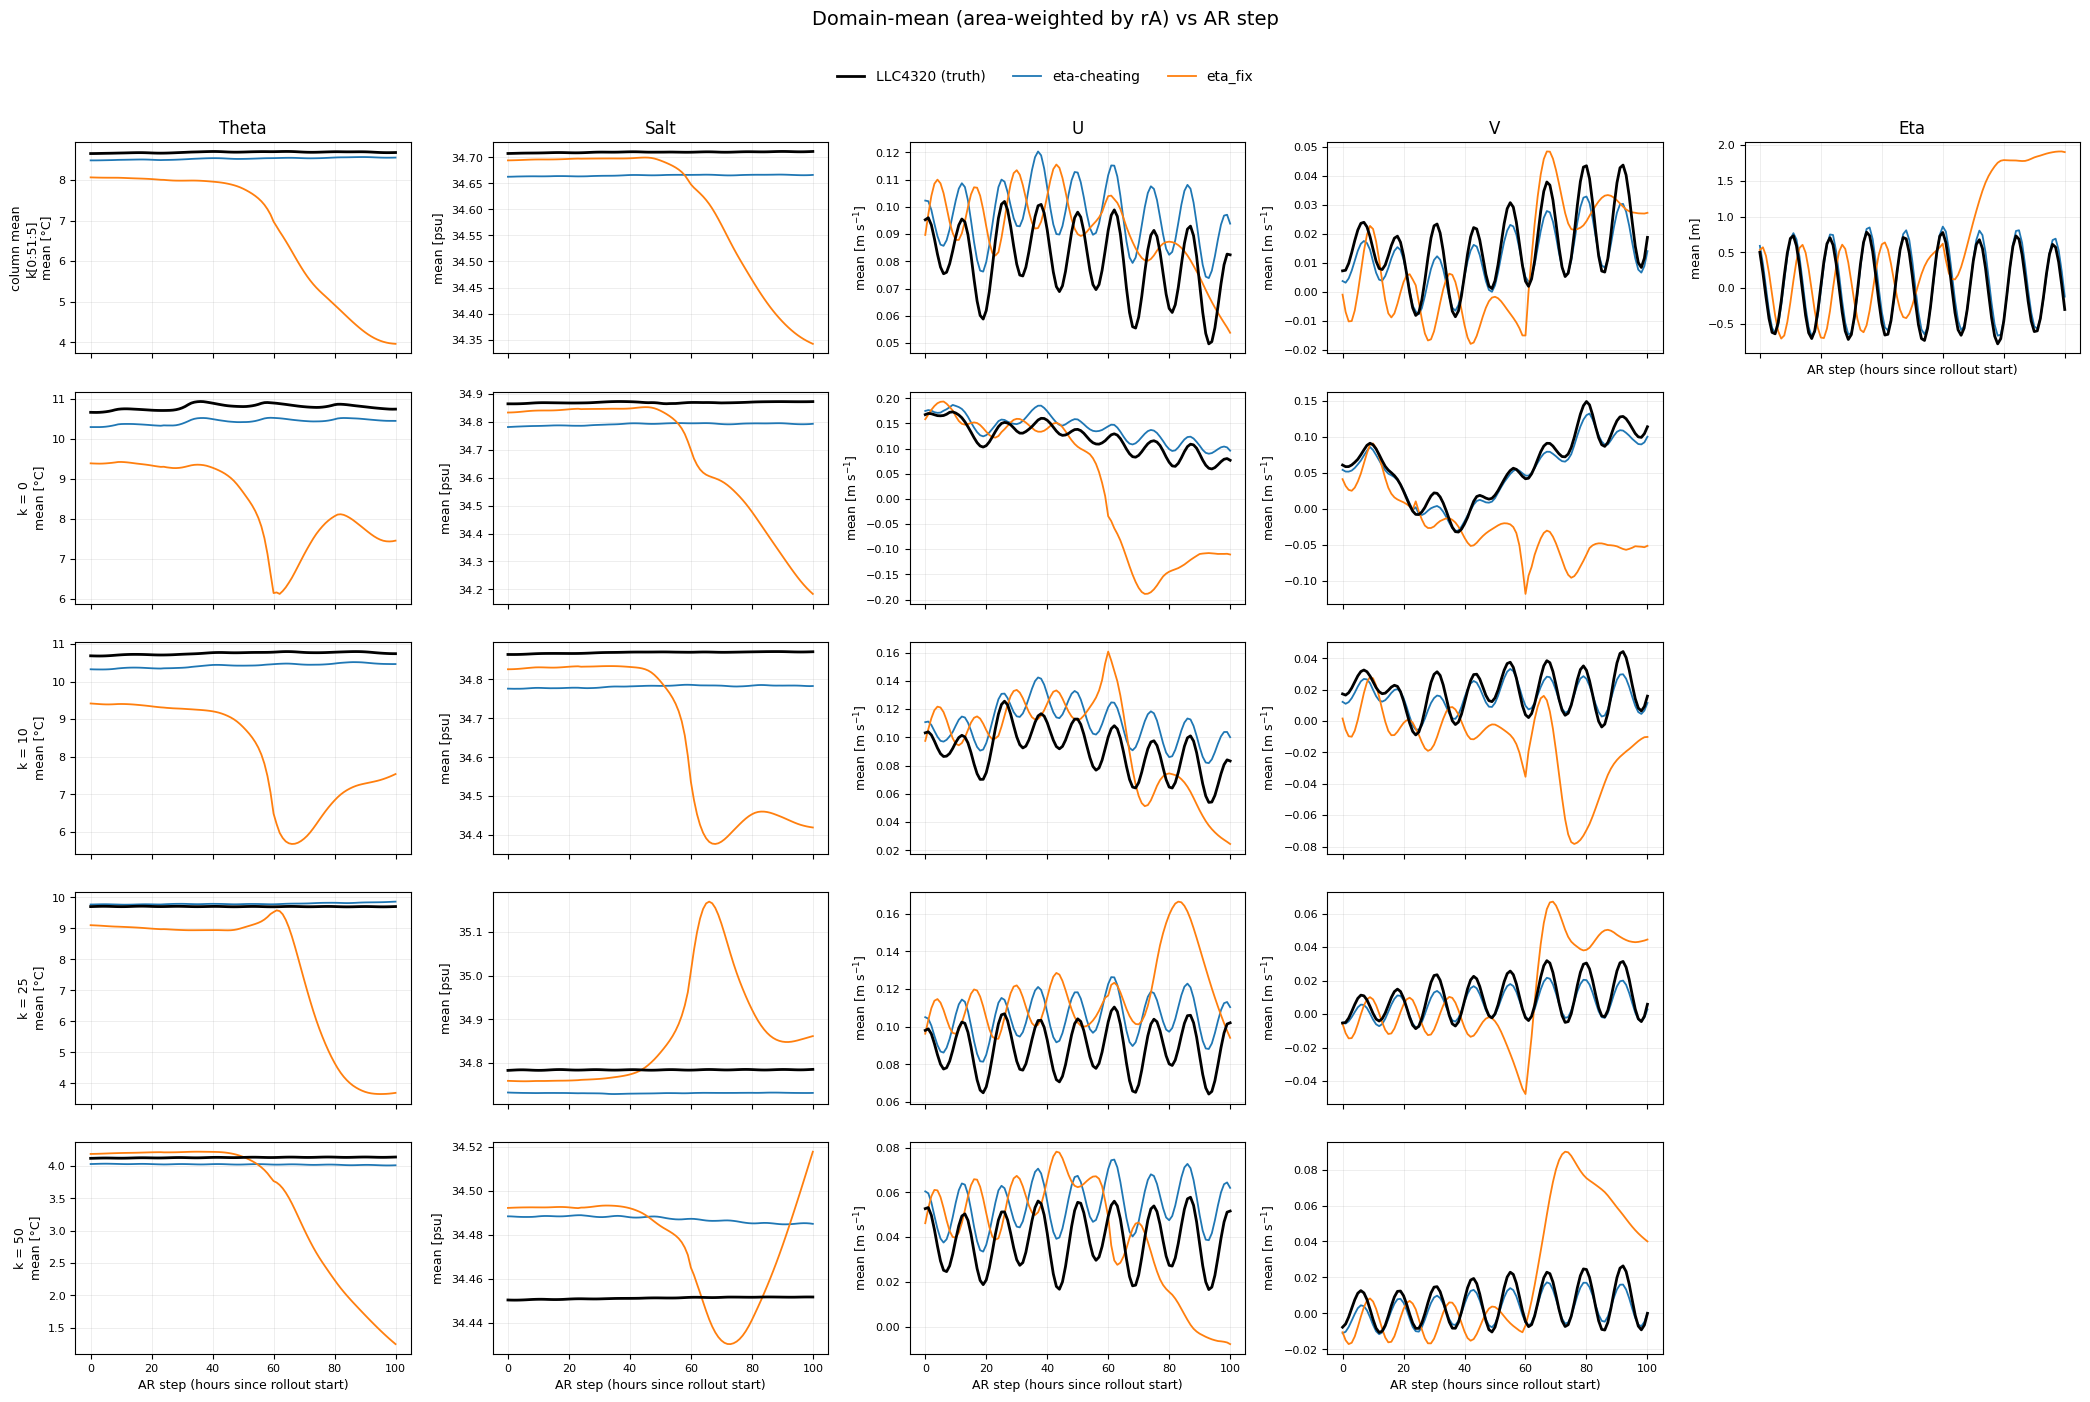

In [28]:
# ============== 1. DOMAIN MEAN ==============
plot_stat('mean', 'Domain-mean (area-weighted by rA) vs AR step', 'AR-stability_domain-mean', 'mean [{u}]')

saved figs/AR-stability/AR-stability_domain-std.png


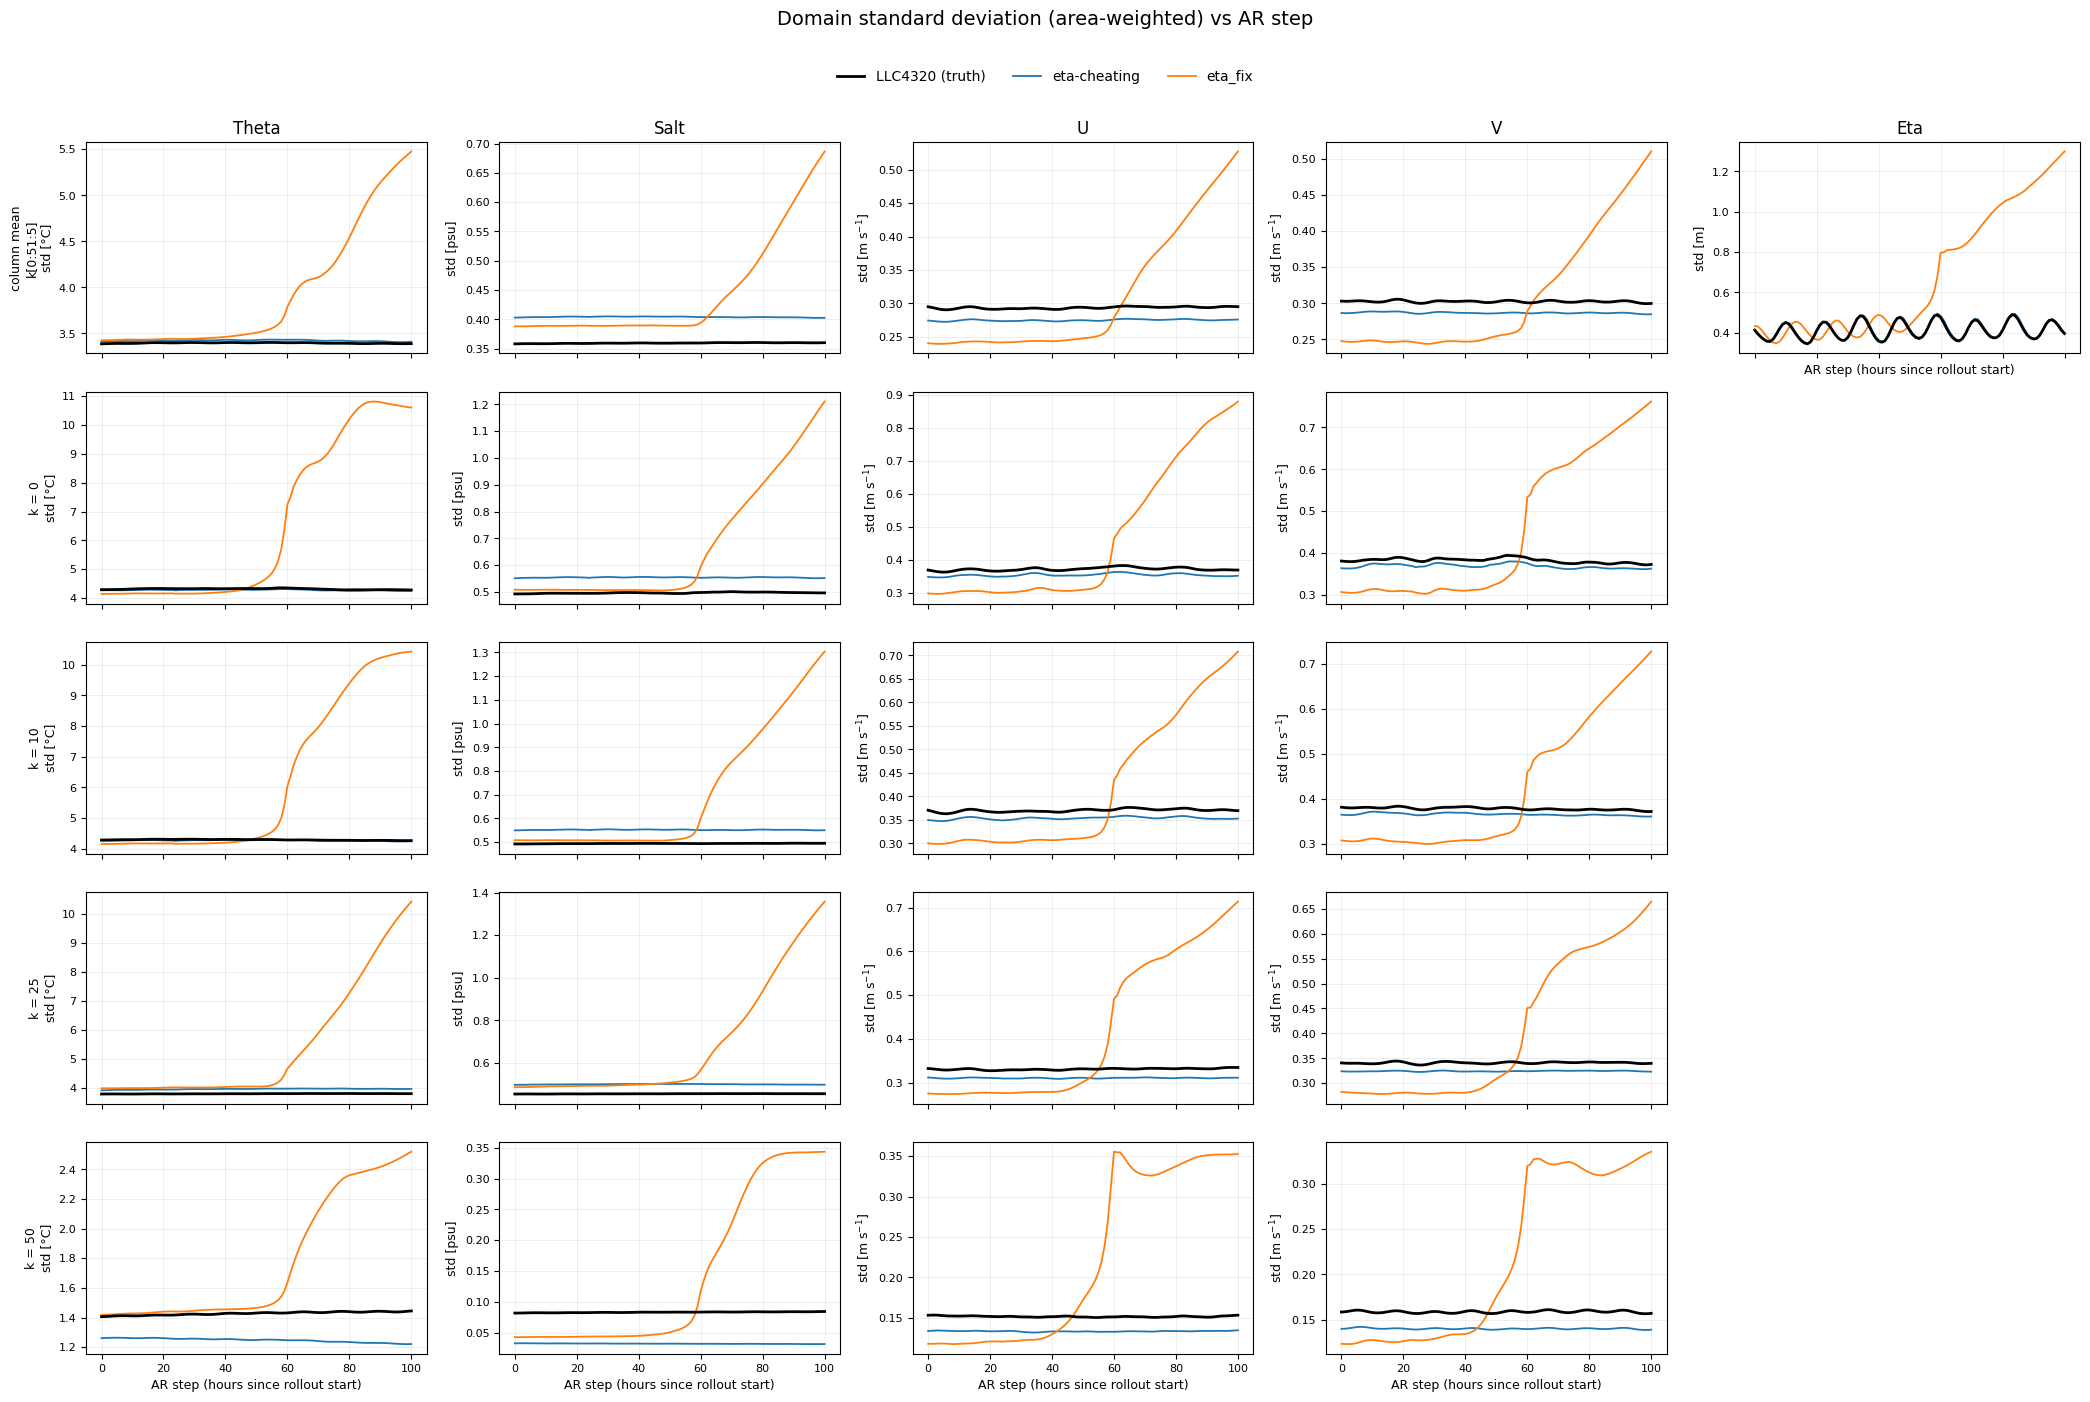

In [29]:
# ============== 2. DOMAIN STD ==============
plot_stat('std', 'Domain standard deviation (area-weighted) vs AR step', 'AR-stability_domain-std', 'std [{u}]')

saved figs/AR-stability/AR-stability_rmse.png


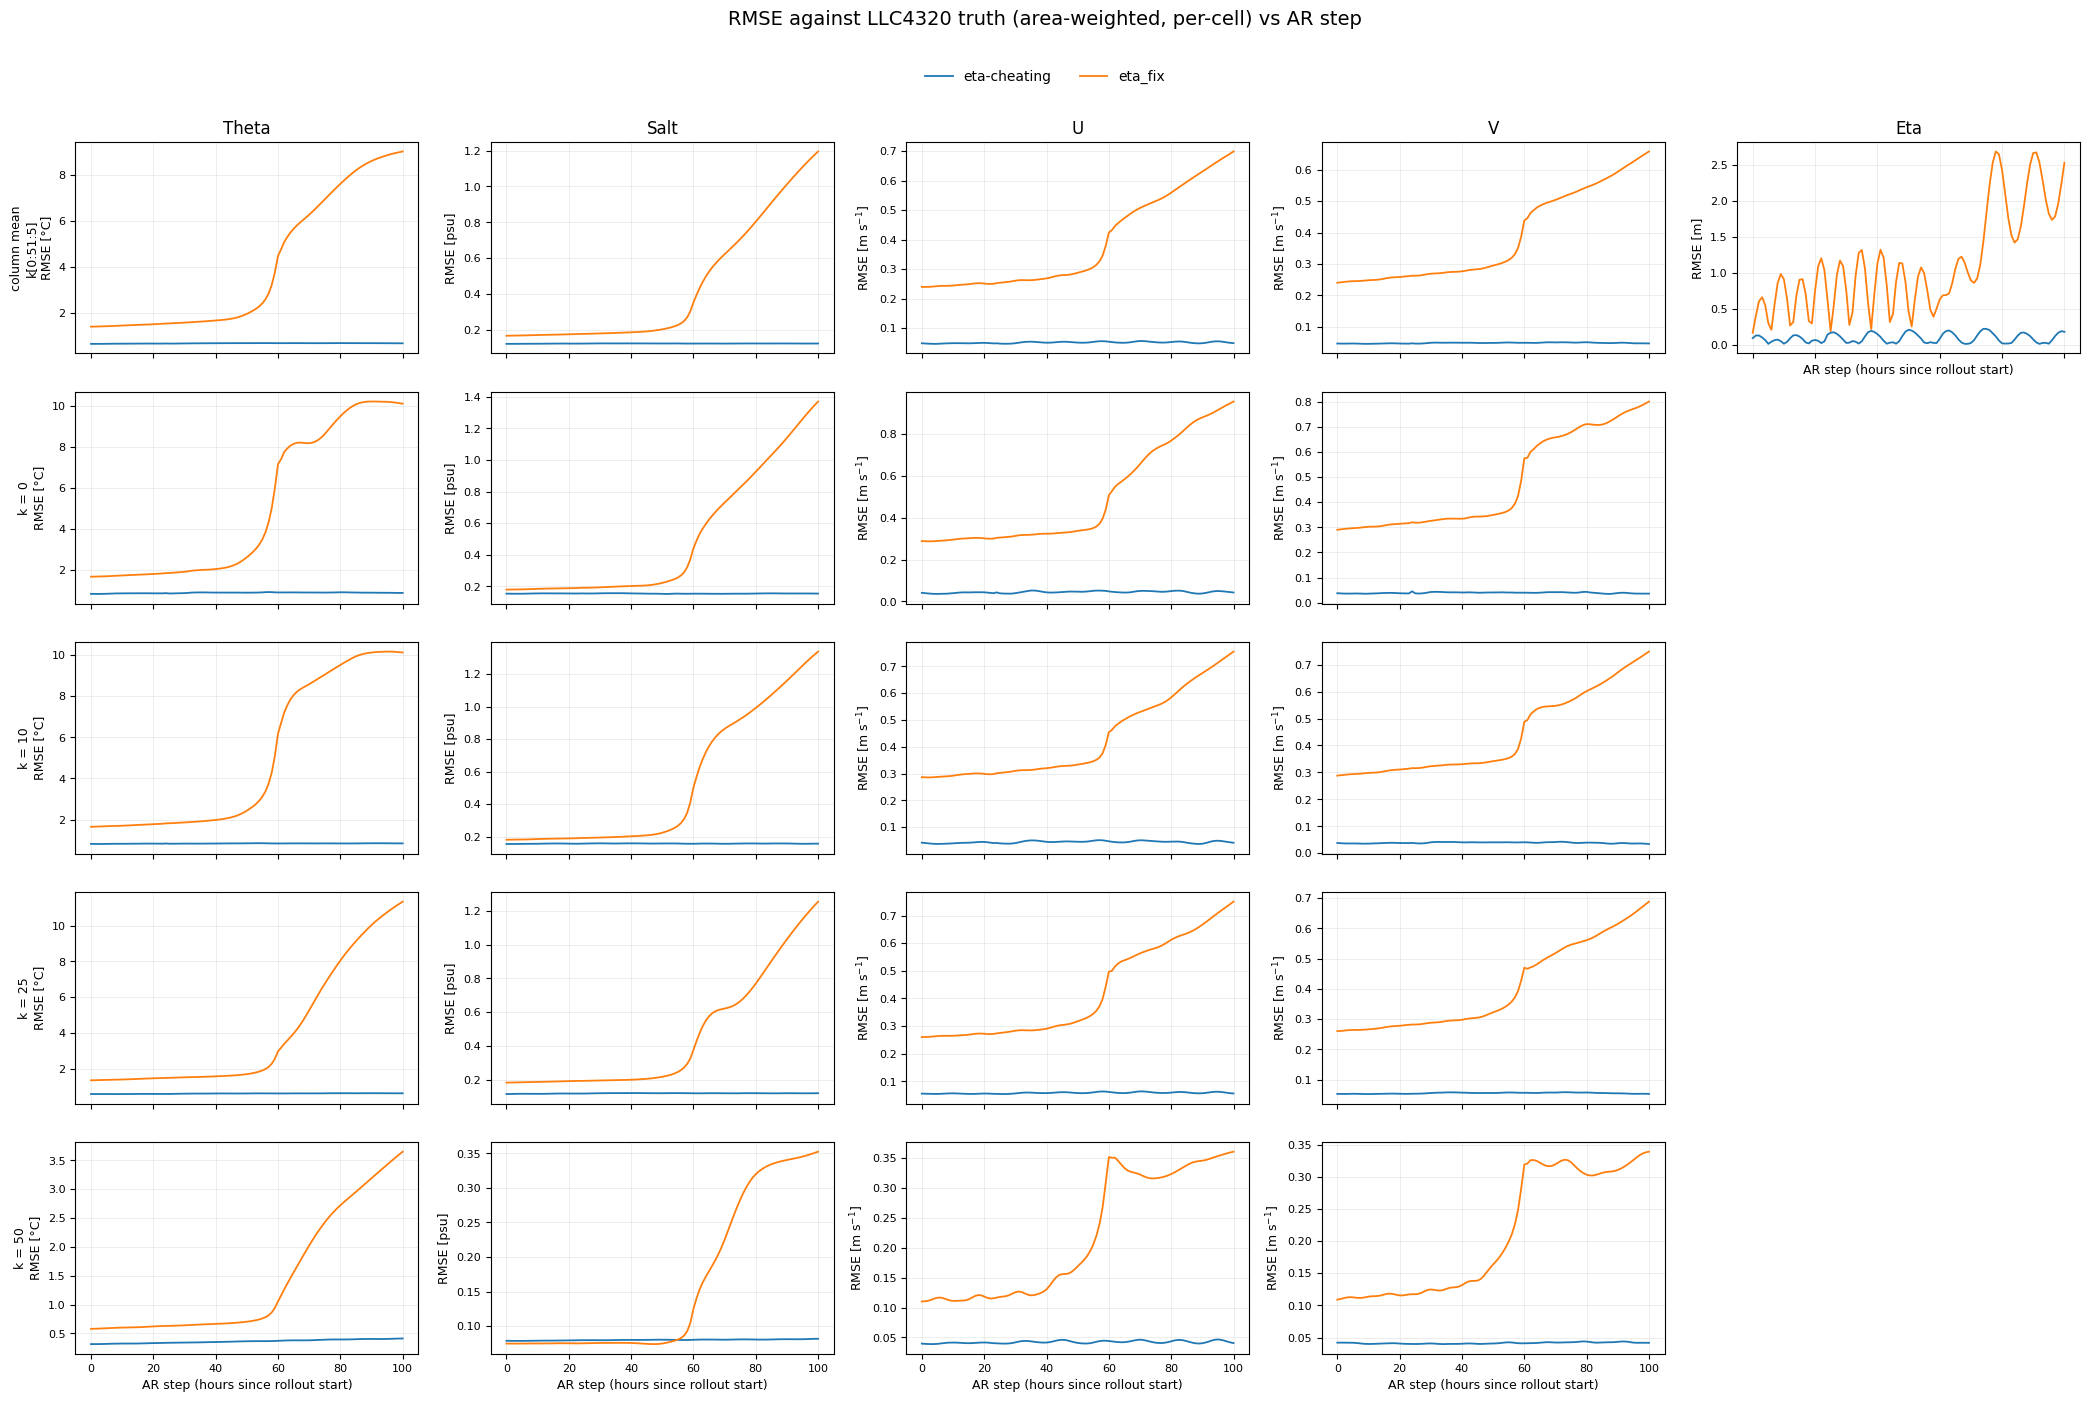

In [30]:
# ============== 3. RMSE vs LLC ==============
plot_stat('rmse', 'RMSE against LLC4320 truth (area-weighted, per-cell) vs AR step', 'AR-stability_rmse', 'RMSE [{u}]')